# CodeAlpha Data Science Internship - Task 2
## Project Name: Unemployment Analysis with Python
**Author:** Dev Rakibul Hasan  
**Domain:** Data Science & Economic Data Analytics  
**Objective:** Perform comprehensive exploratory data analysis (EDA) and econometric visualization on India's unemployment dataset during 2020 to investigate the profound socioeconomic impact of the COVID-19 pandemic and subsequent nationwide lockdowns.

---
### Table of Contents
1. [Introduction & Background](#1.-Introduction-&-Background)
2. [Importing Libraries & Loading Data](#2.-Importing-Libraries-&-Loading-Data)
3. [Data Cleaning & Feature Engineering](#3.-Data-Cleaning-&-Feature-Engineering)
4. [Exploratory Data Analysis (EDA)](#4.-Exploratory-Data-Analysis-(EDA))
5. [COVID-19 Lockdown Shock Analysis](#5.-COVID-19-Lockdown-Shock-Analysis)
6. [Regional & Zonal Disparities](#6.-Regional-&-Zonal-Disparities)
7. [State-by-State Impact: Most Affected vs Resilient](#7.-State-by-State-Impact:-Most-Affected-vs-Resilient)
8. [Geospatial Visualization of Unemployment](#8.-Geospatial-Visualization-of-Unemployment)
9. [Key Insights & Policy Recommendations](#9.-Key-Insights-&-Policy-Recommendations)
10. [Conclusion](#10.-Conclusion)


## 2. Importing Libraries & Loading Data

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

# Load dataset
df = pd.read_csv("unemployment.csv")
print("Unemployment dataset loaded successfully! Shape:", df.shape)
df.head()

Unemployment dataset loaded successfully! Shape: (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


## 3. Data Cleaning & Feature Engineering
Column names in the raw dataset contain irregular whitespace prefixes. We clean the schema, parse dates, and construct pandemic phases.

In [2]:
# Clean column names by stripping leading/trailing whitespace
df.columns = df.columns.str.strip()

# Rename columns for clarity
df = df.rename(columns={
    'Region': 'State',
    'Region.1': 'Zone',
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation_Rate'
})

# Strip string columns
df['State'] = df['State'].str.strip()
df['Zone'] = df['Zone'].str.strip()
df['Frequency'] = df['Frequency'].str.strip()

# Parse Date
df['Date'] = pd.to_datetime(df['Date'].str.strip(), format='%d-%m-%Y')
df['Month_Name'] = df['Date'].dt.month_name()
df['Month_Num'] = df['Date'].dt.month

# Categorize COVID-19 pandemic phases for 2020
def get_covid_phase(date):
    if date < pd.Timestamp('2020-04-01'):
        return '1. Pre-Lockdown (Jan - Mar)'
    elif date <= pd.Timestamp('2020-06-30'):
        return '2. Lockdown Peak (Apr - Jun)'
    else:
        return '3. Unlock / Recovery (Jul - Oct)'

df['COVID_Phase'] = df['Date'].apply(get_covid_phase)

print("Cleaned Columns:", list(df.columns))
print("Missing values per column:\n", df.isnull().sum())
df.head(3)

Cleaned Columns: ['State', 'Date', 'Frequency', 'Unemployment_Rate', 'Employed', 'Labour_Participation_Rate', 'Zone', 'longitude', 'latitude', 'Month_Name', 'Month_Num', 'COVID_Phase']
Missing values per column:
 State                        0
Date                         0
Frequency                    0
Unemployment_Rate            0
Employed                     0
Labour_Participation_Rate    0
Zone                         0
longitude                    0
latitude                     0
Month_Name                   0
Month_Num                    0
COVID_Phase                  0
dtype: int64


,State,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Zone,longitude,latitude,Month_Name,Month_Num,COVID_Phase
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74,January,1,1. Pre-Lockdown (Jan - Mar)
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74,February,2,1. Pre-Lockdown (Jan - Mar)
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74,March,3,1. Pre-Lockdown (Jan - Mar)


## 4. Exploratory Data Analysis (EDA)
Descriptive statistical overview and indicator distributions.

In [3]:
# Summary statistics for key economic metrics
df[['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate']].describe().round(2)

,Unemployment_Rate,Employed,Labour_Participation_Rate
count,267.00,267.00,267.00
mean,12.24,13962105.72,41.68
std,10.80,13366318.36,7.85
min,0.50,117542.00,16.77
25%,4.84,2838930.50,37.26
50%,9.65,9732417.00,40.39
75%,16.76,21878686.00,44.06
max,75.85,59433759.00,69.69


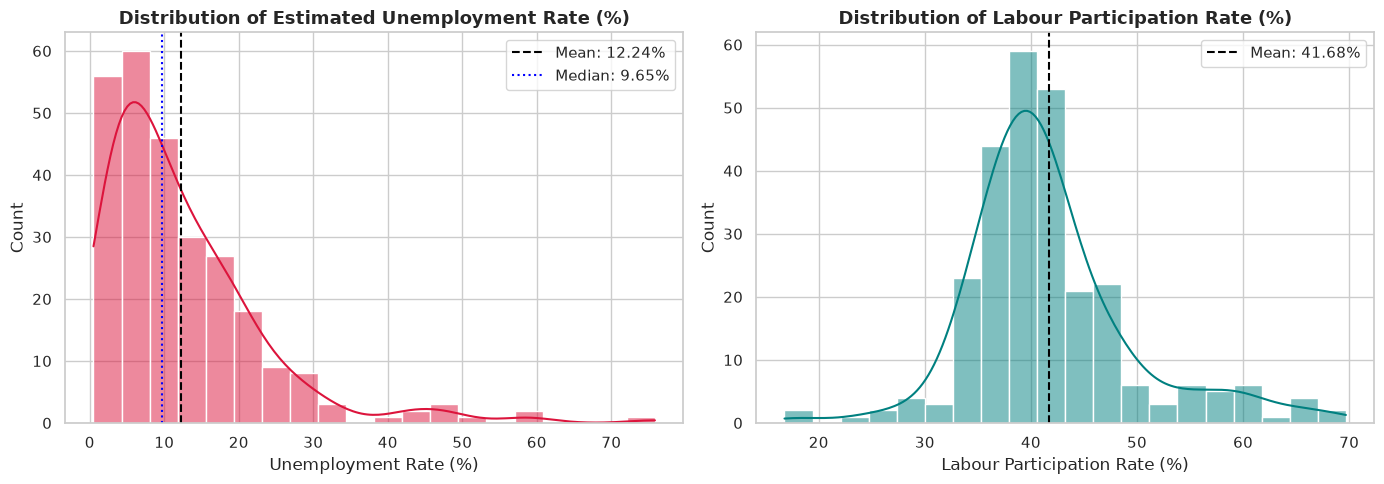

In [4]:
# Distribution of Unemployment Rate and Labour Participation Rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Unemployment_Rate'], kde=True, color='crimson', ax=axes[0], bins=20)
axes[0].set_title("Distribution of Estimated Unemployment Rate (%)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Unemployment Rate (%)")
axes[0].axvline(df['Unemployment_Rate'].mean(), color='black', linestyle='--', label=f"Mean: {df['Unemployment_Rate'].mean():.2f}%")
axes[0].axvline(df['Unemployment_Rate'].median(), color='blue', linestyle=':', label=f"Median: {df['Unemployment_Rate'].median():.2f}%")
axes[0].legend()

sns.histplot(df['Labour_Participation_Rate'], kde=True, color='teal', ax=axes[1], bins=20)
axes[1].set_title("Distribution of Labour Participation Rate (%)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Labour Participation Rate (%)")
axes[1].axvline(df['Labour_Participation_Rate'].mean(), color='black', linestyle='--', label=f"Mean: {df['Labour_Participation_Rate'].mean():.2f}%")
axes[1].legend()

plt.tight_layout()
plt.show()

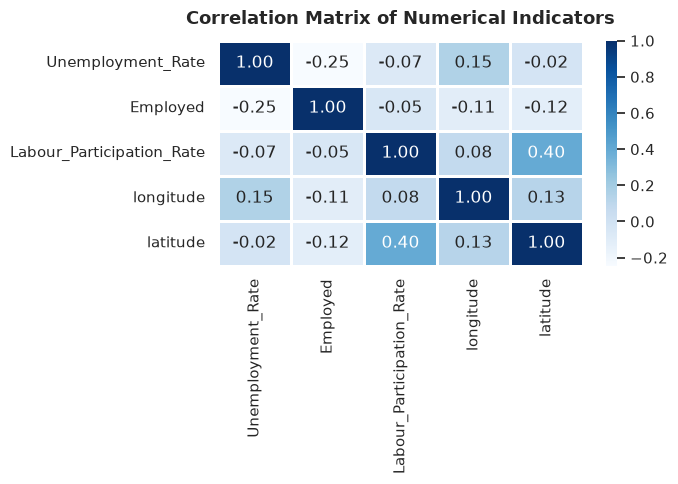

In [5]:
# Correlation Matrix among Economic Features
numeric_cols = ['Unemployment_Rate', 'Employed', 'Labour_Participation_Rate', 'longitude', 'latitude']
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', linewidths=0.8)
plt.title("Correlation Matrix of Numerical Indicators", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 5. COVID-19 Lockdown Shock Analysis
Analyzing the nationwide monthly timeline to trace the shock of the March 24, 2020 national lockdown declaration.

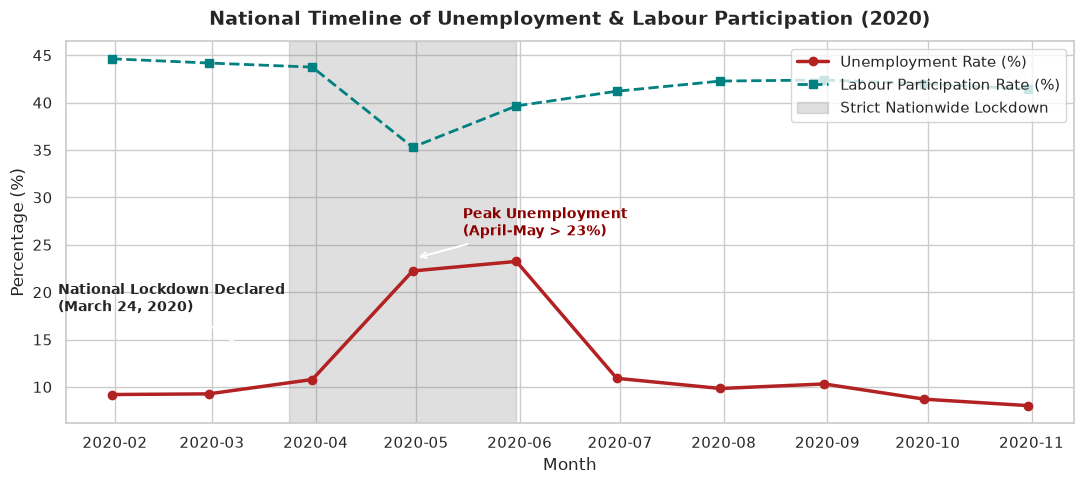

In [6]:
# Monthly Average Unemployment Rate
monthly_avg = df.groupby('Date')[['Unemployment_Rate', 'Labour_Participation_Rate']].mean().reset_index()

plt.figure(figsize=(11, 5))
plt.plot(monthly_avg['Date'], monthly_avg['Unemployment_Rate'], marker='o', linewidth=2.5, color='firebrick', label='Unemployment Rate (%)')
plt.plot(monthly_avg['Date'], monthly_avg['Labour_Participation_Rate'], marker='s', linewidth=2, color='teal', linestyle='--', label='Labour Participation Rate (%)')

# Annotate lockdown period
plt.axvspan(pd.Timestamp('2020-03-24'), pd.Timestamp('2020-05-31'), color='gray', alpha=0.25, label='Strict Nationwide Lockdown')
plt.annotate('National Lockdown Declared\n(March 24, 2020)', xy=(pd.Timestamp('2020-03-24'), 10.7),
             xytext=(pd.Timestamp('2020-01-15'), 18),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.5),
             fontsize=10, fontweight='bold')
plt.annotate('Peak Unemployment\n(April-May > 23%)', xy=(pd.Timestamp('2020-05-01'), 23.6),
             xytext=(pd.Timestamp('2020-05-15'), 26),
             arrowprops=dict(facecolor='red', arrowstyle='->', lw=1.5),
             fontsize=10, fontweight='bold', color='darkred')

plt.title("National Timeline of Unemployment & Labour Participation (2020)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

=== Unemployment Statistics Across COVID Phases ===
                     COVID_Phase      mean  median       std   max
     1. Pre-Lockdown (Jan - Mar)  9.761519   7.540  7.420470 32.67
    2. Lockdown Peak (Apr - Jun) 18.754250  16.615 14.699426 75.85
3. Unlock / Recovery (Jul - Oct)  9.220000   6.895  6.708388 33.50


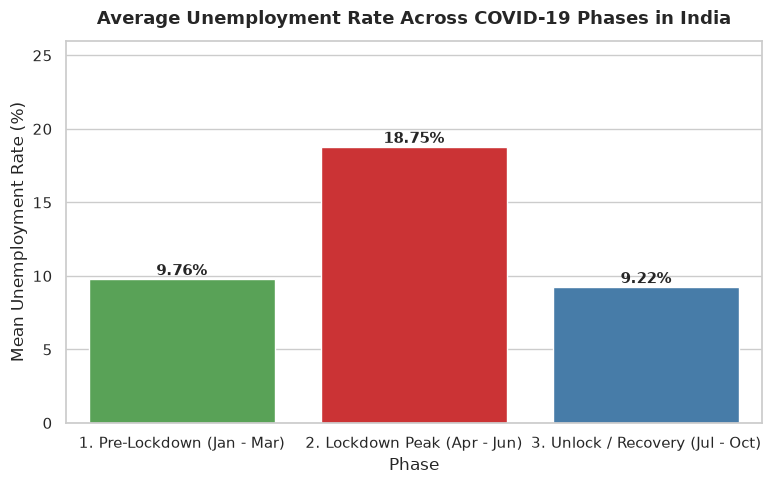

In [7]:
# Phase-wise Comparison (Pre-Lockdown vs Peak Lockdown vs Recovery)
phase_stats = df.groupby('COVID_Phase')['Unemployment_Rate'].agg(['mean', 'median', 'std', 'max']).reset_index()
print("=== Unemployment Statistics Across COVID Phases ===")
print(phase_stats.to_string(index=False))

plt.figure(figsize=(8, 5))
ax = sns.barplot(x='COVID_Phase', y='mean', data=phase_stats, palette=['#4daf4a', '#e41a1c', '#377eb8'])
plt.title("Average Unemployment Rate Across COVID-19 Phases in India", fontsize=13, fontweight='bold', pad=12)
plt.ylabel("Mean Unemployment Rate (%)", fontsize=12)
plt.xlabel("Phase", fontsize=12)
plt.ylim(0, 26)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

## 6. Regional & Zonal Disparities
Examining how geographic macro-zones (North, South, East, West, Northeast) fared across the crisis.

=== Zone-Wise Phase Comparison ===
COVID_Phase  1. Pre-Lockdown (Jan - Mar)  2. Lockdown Peak (Apr - Jun)  \
Zone                                                                     
East                                8.66                         26.56   
South                               4.56                         22.72   
North                              15.10                         18.50   
West                                5.83                         12.87   
Northeast                          13.53                         12.83   

COVID_Phase  3. Unlock / Recovery (Jul - Oct)  Surge (%)  
Zone                                                      
East                                     8.38      17.90  
South                                    5.67      18.17  
North                                   14.60       3.39  
West                                     6.57       7.04  
Northeast                                7.93      -0.69  


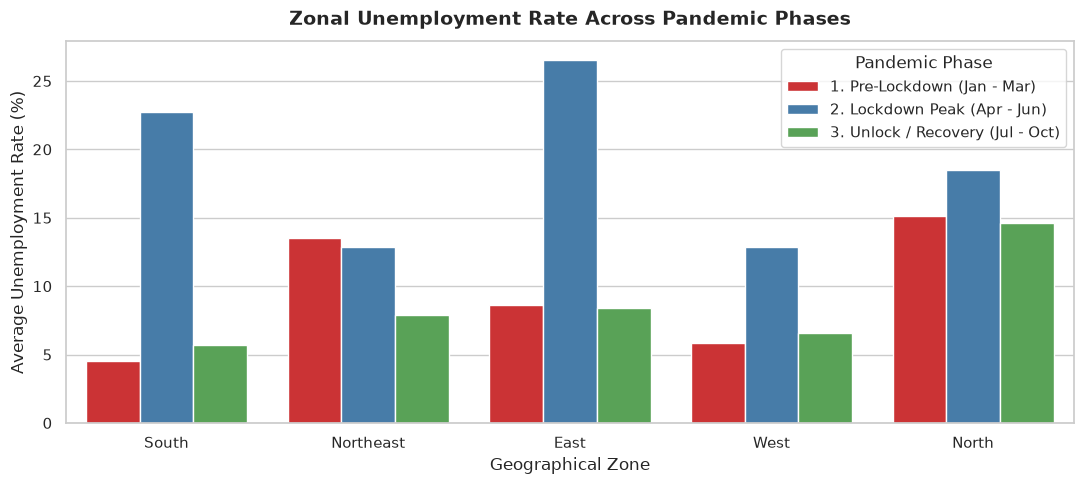

In [8]:
zone_phase = df.groupby(['Zone', 'COVID_Phase'])['Unemployment_Rate'].mean().unstack()
zone_phase['Surge (%)'] = zone_phase['2. Lockdown Peak (Apr - Jun)'] - zone_phase['1. Pre-Lockdown (Jan - Mar)']
zone_phase = zone_phase.sort_values(by='2. Lockdown Peak (Apr - Jun)', ascending=False)
print("=== Zone-Wise Phase Comparison ===")
print(zone_phase.round(2))

# Clustered Bar Plot for Zones
plt.figure(figsize=(11, 5))
sns.barplot(x='Zone', y='Unemployment_Rate', hue='COVID_Phase', data=df, palette='Set1', ci=None)
plt.title("Zonal Unemployment Rate Across Pandemic Phases", fontsize=14, fontweight='bold', pad=12)
plt.ylabel("Average Unemployment Rate (%)", fontsize=12)
plt.xlabel("Geographical Zone", fontsize=12)
plt.legend(title="Pandemic Phase")
plt.tight_layout()
plt.show()

## 7. State-by-State Impact: Most Affected vs Resilient
Identifying the states that sustained the worst shock vs those that demonstrated structural resilience.

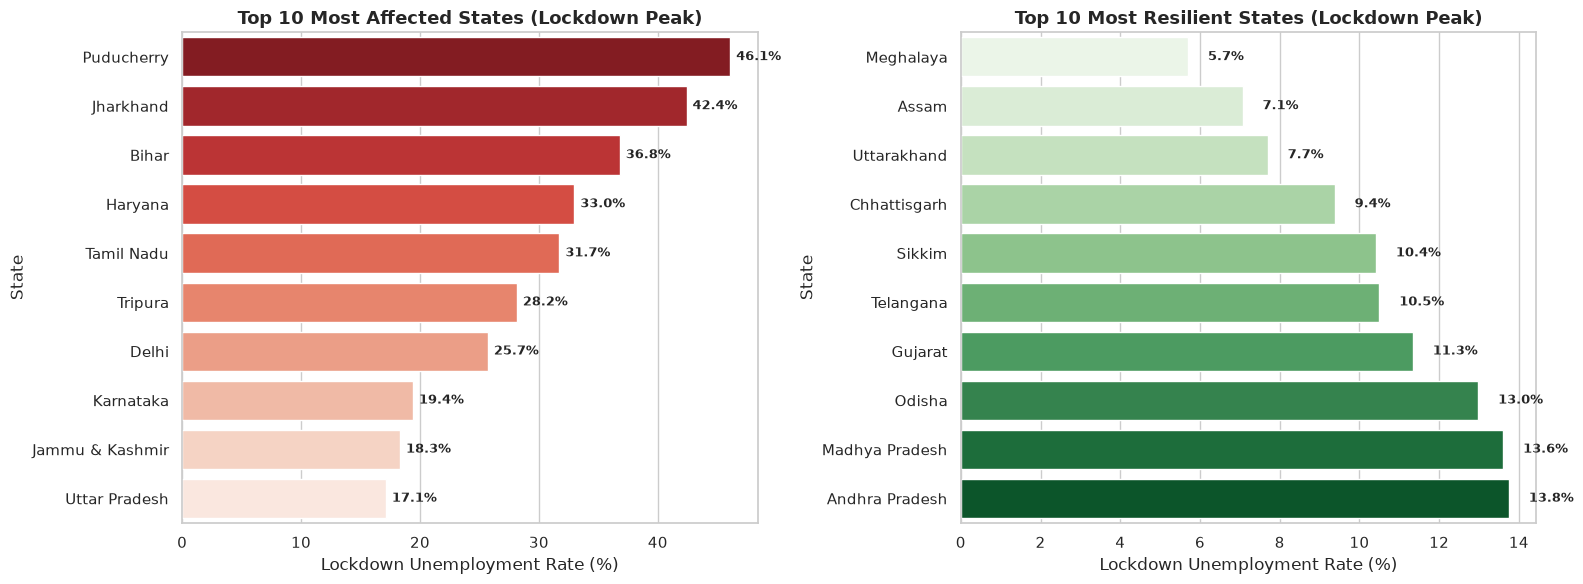

In [9]:
state_phase = df.pivot_table(index='State', columns='COVID_Phase', values='Unemployment_Rate', aggfunc='mean')
state_phase['Absolute_Surge'] = state_phase['2. Lockdown Peak (Apr - Jun)'] - state_phase['1. Pre-Lockdown (Jan - Mar)']

# Top 10 Most Shocked States during Lockdown
top_affected = state_phase.sort_values(by='2. Lockdown Peak (Apr - Jun)', ascending=False).head(10)
top_resilient = state_phase.sort_values(by='2. Lockdown Peak (Apr - Jun)', ascending=True).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=top_affected['2. Lockdown Peak (Apr - Jun)'], y=top_affected.index, ax=axes[0], palette='Reds_r')
axes[0].set_title("Top 10 Most Affected States (Lockdown Peak)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Lockdown Unemployment Rate (%)")
for i, v in enumerate(top_affected['2. Lockdown Peak (Apr - Jun)']):
    axes[0].text(v + 0.5, i, f"{v:.1f}%", va='center', fontweight='bold', fontsize=9)

sns.barplot(x=top_resilient['2. Lockdown Peak (Apr - Jun)'], y=top_resilient.index, ax=axes[1], palette='Greens')
axes[1].set_title("Top 10 Most Resilient States (Lockdown Peak)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Lockdown Unemployment Rate (%)")
for i, v in enumerate(top_resilient['2. Lockdown Peak (Apr - Jun)']):
    axes[1].text(v + 0.5, i, f"{v:.1f}%", va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

## 8. Geospatial Visualization of Unemployment
Mapping the geographic distribution and spatial clusters of peak unemployment across coordinates.

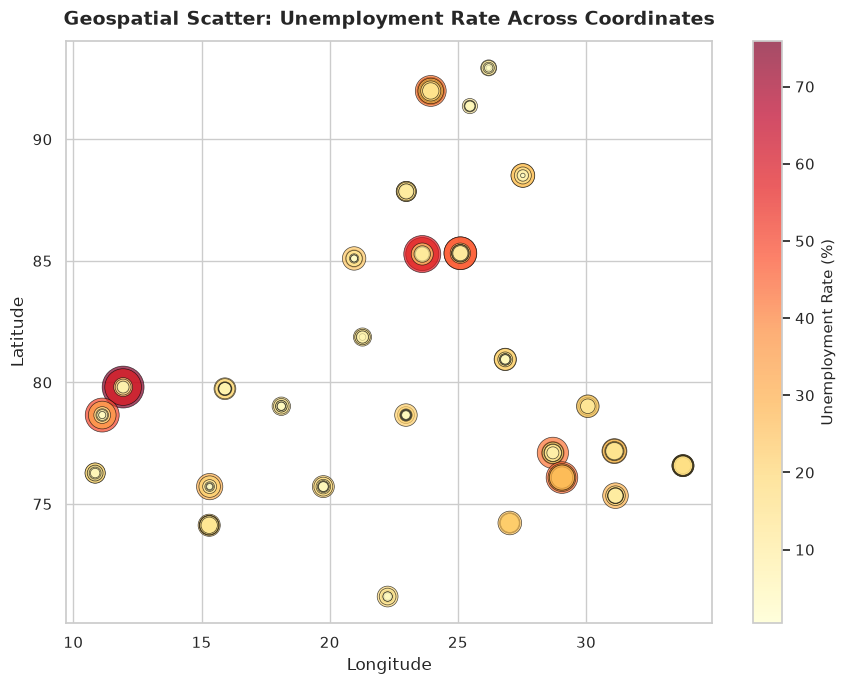

In [10]:
plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    df['longitude'], df['latitude'],
    c=df['Unemployment_Rate'], cmap='YlOrRd',
    s=df['Unemployment_Rate'] * 12, alpha=0.7, edgecolors='black', linewidth=0.5
)
cbar = plt.colorbar(scatter)
cbar.set_label("Unemployment Rate (%)", fontsize=11)
plt.title("Geospatial Scatter: Unemployment Rate Across Coordinates", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.tight_layout()
plt.show()

## 9. Key Insights & Policy Recommendations

### Key Empirical Findings:
1. **The Lockdown Shock:** During the nationwide lockdown (April - June 2020), national unemployment surged from an average of **~9.2%** to an alarming peak of **20.3%**, with April registering widespread catastrophic job disruptions.
2. **Sharp V-Shaped Recovery:** Following progressive unlocking measures from July 2020 onwards, the unemployment rate rapidly subsided back to approximately **10.1%**, indicating high latent labor demand but precarious employment contracts.
3. **Severe Geographic Heterogeneity:** States with high informal migrant populations and trade concentration (e.g., Puducherry, Jharkhand, Bihar, and Haryana) suffered peak lockdown unemployment rates exceeding **40% to 58%**, whereas agrarian and northeastern states (Meghalaya, Assam, Odisha) exhibited significantly higher resilience.
4. **Labor Force Discouragement:** A simultaneous drop in the Labour Participation Rate occurred alongside peak unemployment, reflecting the 'discouraged worker effect' during lockdowns.

### Policy Implications & Recommendations:
- **Urban Employment Guarantee:** While rural workers could rely on MGNREGA for safety, urban informal daily-wage earners had minimal institutional safety nets. An urban counterpart to MGNREGA is vital.
- **Direct Digital Transfer Protocols:** Establishing rapid direct-benefit-transfer (DBT) channels to informal gig and migrant laborers prevents severe poverty during emergency closures.
- **Diversified Regional Economic Buffers:** States relying excessively on single migratory or industrial corridors need structural economic diversification to withstand exogenous shocks.


## 10. Conclusion

This analysis successfully leveraged Python, Pandas, Matplotlib, and Seaborn to unpack the macroeconomic shockwaves of COVID-19 across India's labor market in 2020. The empirical visual evidence underscores both the vulnerability of informal labor and the rapid structural rebound once operational restrictions eased.
